In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

#### Testing loop with inherited demand

In [2]:
from app.services.security_class import arrivals_to_demand_grid
from app.services.coverage_dp import solve_coverage_batch_multi, allocate_milp, solve_allocated_multi, effective_grid, coverage_report_multi, fixed_window_solution, MultiAllocation   # MultiAllocation: lo stesso import già usato per allocate_milp

2026-11-23 14:27:34,733 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 14:27:36,244 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 4 workers


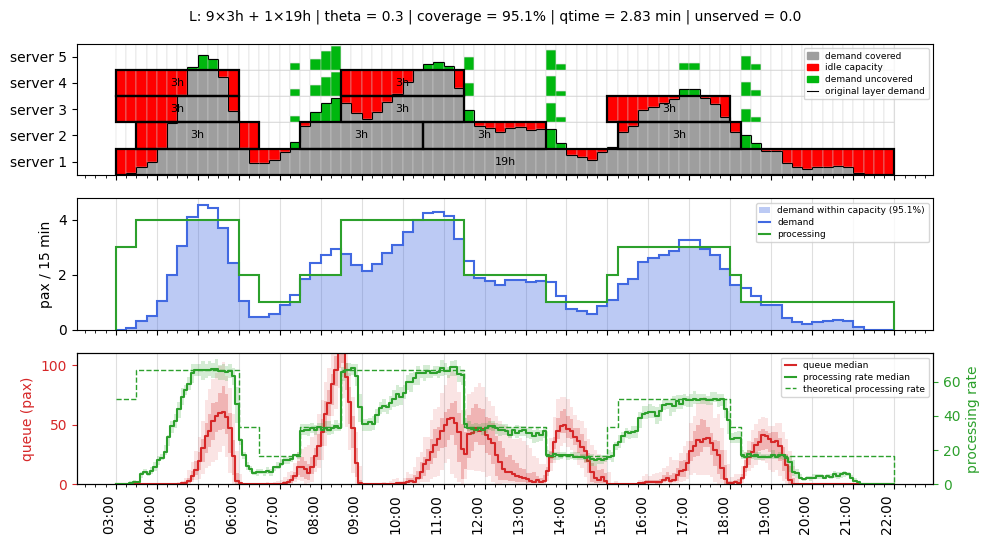

2026-11-23 14:27:51,529 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 4 workers


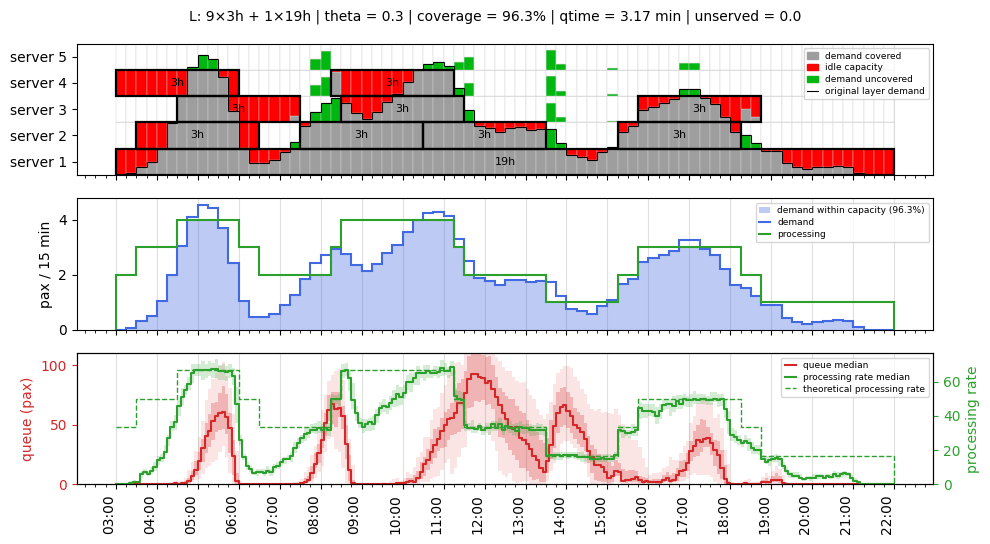

In [32]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, 15)
rates_in_order = [rate_by_label[l] for l in server_labels]

arrivals= samplers.expected_arrivals(flight_demand)

lengths=[12]
theta=0.3
K_total= 1000
length_totals={12:20}

bin_min = 15
step = pd.Timedelta(minutes=bin_min)
day  = pd.Timestamp("2026-06-01")

first = min(arrivals.index[0], day + pd.Timedelta(hours=3))
last  = max(arrivals.index[-1], day + pd.Timedelta(hours=22) - step)
arrivals = arrivals.reindex(pd.date_range(first, last, freq=f"{bin_min}min"), fill_value=0.0)

grid = arrivals_to_demand_grid(arrivals, utils.mean_processing_rate(server_registry))
time_values = pd.DatetimeIndex(arrivals.index)
T = grid.shape[1]
g0 = time_values[0]

start_slot = int((day + pd.Timedelta(hours=3)  - g0) / step)    # 3
end_slot   = int((day + pd.Timedelta(hours=22) - g0) / step)    # 75 = T
assert 0 <= start_slot < end_slot <= T
bounds = (start_slot, end_slot)

fixed = {0: fixed_window_solution(grid[0], theta, start_slot, end_slot - start_slot)}
n_fixed = len(fixed)

curves     = solve_coverage_batch_multi(grid[n_fixed:], lengths, theta, bounds=bounds)
alloc_free = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
alloc = MultiAllocation(
    k=np.vstack([np.zeros((n_fixed, len(lengths)), dtype=int), alloc_free.k]),
    lengths=alloc_free.lengths, value=alloc_free.value,
    per_row_value=np.concatenate([np.zeros(n_fixed), alloc_free.per_row_value]))

# senza domanda ereditata-----
sols = solve_allocated_multi(grid, theta, alloc, inherit=False, fixed=fixed, bounds=bounds)

D_eff = effective_grid(grid, [s.coverage for s in sols])

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = [str(r + 1) for r in range(grid.shape[0])]
blocks = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)]
          for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)
proc_plain = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)

t0   = pd.Timestamp(time_values[0])
step = pd.Timedelta(minutes=bin_min)

server_schedule = {
    label: [((t0 + int(s)*step).to_pydatetime(),
             (t0 + (int(s)+int(l))*step).to_pydatetime())
            for s, l in bl]
    for label, bl in blocks.items() if len(bl)
}

sim = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(server_schedule),
    server_registry=server_registry)
sim_results = sim.run(n_scenarios=50, n_workers=4, timebin=5, base_seed=base_seed)
pax1= sim_results.df_pax
cdf1= sim_results.df_queue_cdf
max_queue= int(max(sim_results.df_timeline.queue_length_mean))
plotutils.plot_blocks(D=D_eff, D_ref=grid, blocks=blocks, labels=labels, time_values=time_values,
                    theta=theta, bin_minutes=15, demand_curve=rho, processing_curve=proc_plain,
                    df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis, queue_max=max_queue)

# con domanda ereditata-----
sols = solve_allocated_multi(grid, theta, alloc, inherit=True, fixed=fixed, bounds=bounds)

D_eff = effective_grid(grid, [s.coverage for s in sols])

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = [str(r + 1) for r in range(grid.shape[0])]
blocks = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)]
          for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)
proc_inh = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)

# sim
t0   = pd.Timestamp(time_values[0])
step = pd.Timedelta(minutes=bin_min)

server_schedule = {
    label: [((t0 + int(s)*step).to_pydatetime(),
             (t0 + (int(s)+int(l))*step).to_pydatetime())
            for s, l in bl]
    for label, bl in blocks.items() if len(bl)
}

sim = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(server_schedule),
    server_registry=server_registry)
sim_results = sim.run(n_scenarios=50, n_workers=4, timebin=5, base_seed=base_seed)
pax2= sim_results.df_pax
cdf2= sim_results.df_queue_cdf
plotutils.plot_blocks(D=D_eff, D_ref=grid, blocks=blocks, labels=labels, time_values=time_values,
                    theta=theta, bin_minutes=15, demand_curve=rho, processing_curve=proc_inh,
                    df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis, queue_max=max_queue)

In [33]:
pax1

,date,base_seed,n_scenarios,scenario_id,simulation_start_dt,id,segment,flight_number,flight_departure_dt,arrival_dt,processing_time,server_id,start_dt,end_dt,queue_time,time_to_departure,served
0,2026-06-01,42,50,1,2026-06-01 03:00:00,EN8861_202606010630_standard_54,standard,EN 8861,2026-06-01 06:30:00,2026-06-01 03:26:51.158259,0.622968,1,2026-06-01 03:26:51.158259,2026-06-01 03:27:28.536338,0.000000,182.524394,True
1,2026-06-01,42,50,1,2026-06-01 03:00:00,EN8861_202606010630_standard_49,standard,EN 8861,2026-06-01 06:30:00,2026-06-01 03:33:10.336424,0.607324,3,2026-06-01 03:33:10.336424,2026-06-01 03:33:46.775841,0.000000,176.220403,True
2,2026-06-01,42,50,1,2026-06-01 03:00:00,V71705_202606010615_standard_5,standard,V7 1705,2026-06-01 06:15:00,2026-06-01 03:35:25.971656,0.618495,4,2026-06-01 03:35:25.971656,2026-06-01 03:36:03.081358,0.000000,158.948644,True
3,2026-06-01,42,50,1,2026-06-01 03:00:00,EN8861_202606010630_standard_30,standard,EN 8861,2026-06-01 06:30:00,2026-06-01 03:37:10.963642,0.134353,1,2026-06-01 03:37:10.963642,2026-06-01 03:37:19.024803,0.000000,172.682920,True
4,2026-06-01,42,50,1,2026-06-01 03:00:00,EN8861_202606010630_standard_91,standard,EN 8861,2026-06-01 06:30:00,2026-06-01 03:38:19.797308,0.089881,2,2026-06-01 03:38:19.797308,2026-06-01 03:38:25.190144,0.000000,171.580164,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345395,2026-06-01,42,50,50,2026-06-01 03:00:00,VY6028_202606012200_standard_67,standard,VY 6028,2026-06-01 22:00:00,2026-06-01 21:03:52.133243,0.119536,1,2026-06-01 21:03:52.133243,2026-06-01 21:03:59.305416,0.000000,56.011576,True
345396,2026-06-01,42,50,50,2026-06-01 03:00:00,VY6028_202606012200_standard_33,standard,VY 6028,2026-06-01 22:00:00,2026-06-01 21:04:11.173022,0.261829,1,2026-06-01 21:04:11.173022,2026-06-01 21:04:26.882790,0.000000,55.551953,True
345397,2026-06-01,42,50,50,2026-06-01 03:00:00,VY6028_202606012200_standard_105,standard,VY 6028,2026-06-01 22:00:00,2026-06-01 21:04:25.330893,0.171879,1,2026-06-01 21:04:26.882790,2026-06-01 21:04:37.195545,0.025865,55.380074,True
345398,2026-06-01,42,50,50,2026-06-01 03:00:00,VY6028_202606012200_standard_7,standard,VY 6028,2026-06-01 22:00:00,2026-06-01 21:05:03.961479,0.433957,1,2026-06-01 21:05:03.961479,2026-06-01 21:05:29.998920,0.000000,54.500018,True


In [35]:
merge_pax = pd.merge(pax1, pax2, on=['scenario_id', 'id'], suffixes=('_plain', '_inherited'), how='outer', indicator=True)
merge_pax['queue_time_diff'] = merge_pax['queue_time_inherited'] - merge_pax['queue_time_plain']
merge_pax

,date_plain,base_seed_plain,n_scenarios_plain,scenario_id,simulation_start_dt_plain,id,segment_plain,flight_number_plain,flight_departure_dt_plain,arrival_dt_plain,...,arrival_dt_inherited,processing_time_inherited,server_id_inherited,start_dt_inherited,end_dt_inherited,queue_time_inherited,time_to_departure_inherited,served_inherited,_merge,queue_time_diff
0,2026-06-01,42,50,1,2026-06-01 03:00:00,AF1067_202606010950_standard_0,standard,AF 1067,2026-06-01 09:50:00,2026-06-01 08:37:52.893506,...,2026-06-01 08:37:52.893506,0.163528,2,2026-06-01 08:40:04.042101,2026-06-01 08:40:13.853776,2.185810,69.769104,True,both,-4.428517
1,2026-06-01,42,50,1,2026-06-01 03:00:00,AF1067_202606010950_standard_1,standard,AF 1067,2026-06-01 09:50:00,2026-06-01 08:17:52.302693,...,2026-06-01 08:17:52.302693,0.086121,2,2026-06-01 08:25:32.750306,2026-06-01 08:25:37.917584,7.674127,84.368040,True,both,-5.526997
2,2026-06-01,42,50,1,2026-06-01 03:00:00,AF1067_202606010950_standard_10,standard,AF 1067,2026-06-01 09:50:00,2026-06-01 07:31:36.999515,...,2026-06-01 07:31:36.999515,0.374290,2,2026-06-01 07:32:45.876705,2026-06-01 07:33:08.334088,1.147953,136.861099,True,both,-3.705296
3,2026-06-01,42,50,1,2026-06-01 03:00:00,AF1067_202606010950_standard_100,standard,AF 1067,2026-06-01 09:50:00,2026-06-01 08:00:36.503024,...,2026-06-01 08:00:36.503024,0.086929,2,2026-06-01 08:11:07.790758,2026-06-01 08:11:13.006486,10.521462,98.783225,True,both,-1.342318
4,2026-06-01,42,50,1,2026-06-01 03:00:00,AF1067_202606010950_standard_101,standard,AF 1067,2026-06-01 09:50:00,2026-06-01 08:06:01.844668,...,2026-06-01 08:06:01.844668,0.088644,1,2026-06-01 08:16:25.711872,2026-06-01 08:16:31.030503,10.397787,93.482825,True,both,-2.103768
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345395,2026-06-01,42,50,50,2026-06-01 03:00:00,XZ2385_202606011200_standard_76,standard,XZ 2385,2026-06-01 12:00:00,2026-06-01 09:34:47.263255,...,2026-06-01 09:34:47.263255,1.029494,1,2026-06-01 09:34:52.785778,2026-06-01 09:35:54.555401,0.092042,144.090743,True,both,0.000000
345396,2026-06-01,42,50,50,2026-06-01 03:00:00,XZ2385_202606011200_standard_77,standard,XZ 2385,2026-06-01 12:00:00,2026-06-01 10:42:32.107817,...,2026-06-01 10:42:32.107817,0.156801,4,2026-06-01 10:43:18.523474,2026-06-01 10:43:27.931523,0.773594,76.534475,True,both,0.000000
345397,2026-06-01,42,50,50,2026-06-01 03:00:00,XZ2385_202606011200_standard_78,standard,XZ 2385,2026-06-01 12:00:00,2026-06-01 10:32:49.235601,...,2026-06-01 10:32:49.235601,0.566558,1,2026-06-01 10:34:41.550135,2026-06-01 10:35:15.543639,1.871909,84.740939,True,both,0.000000
345398,2026-06-01,42,50,50,2026-06-01 03:00:00,XZ2385_202606011200_standard_8,standard,XZ 2385,2026-06-01 12:00:00,2026-06-01 10:41:16.063913,...,2026-06-01 10:41:16.063913,0.137157,1,2026-06-01 10:41:55.295973,2026-06-01 10:42:03.525420,0.653868,77.941243,True,both,0.000000


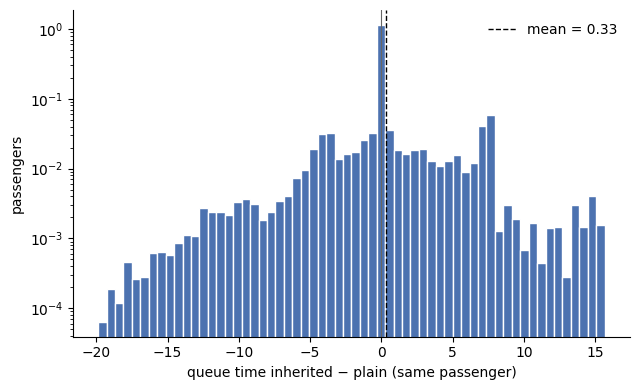

In [45]:
d = merge_pax.loc[merge_pax["_merge"] == "both", "queue_time_diff"].dropna()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(d, bins=60, density=True, color="#4c72b0", edgecolor="white")
ax.axvline(0, color="#666", lw=0.8)
ax.axvline(d.mean(), color="k", ls="--", lw=1, label=f"mean = {d.mean():.2f}")
ax.set_yscale("log")
ax.set_xlabel("queue time inherited − plain (same passenger)"); ax.set_ylabel("passengers")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

          plain  inherited
mean      2.969      3.310
p50       1.488      1.417
p90       7.843      8.734
p95      10.635     13.000
p99      15.261     19.902
P(W>10)   0.059      0.080
P(W>15)   0.011      0.035


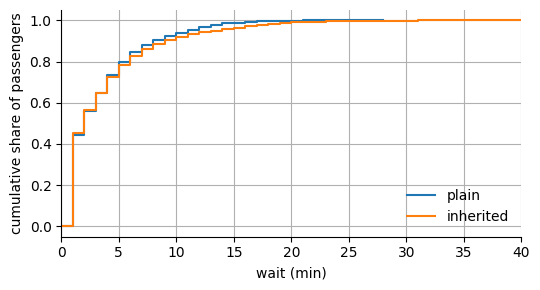

In [37]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def _cdf(c):
    e = np.r_[c["queue_time_bin_start"].iloc[0], c["queue_time_bin_end"].values].astype(float)
    n = c["cum_count"].values.astype(float)
    return e, np.r_[0.0, n / n[-1]]

def cdf_table(cdfs, labels, qs=(0.5, 0.9, 0.95, 0.99), thr=(10, 15)):
    rows = {}
    for c, lab in zip(cdfs, labels):
        e, p = _cdf(c)
        r = {"mean": (np.diff(p) * (e[:-1] + e[1:]) / 2).sum()}
        r.update({f"p{int(q*100)}": np.interp(q, p, e) for q in qs})
        r.update({f"P(W>{x})": 1 - np.interp(x, e, p) for x in thr})
        rows[lab] = r
    return pd.DataFrame(rows).round(3)

def plot_cdfs(cdfs, labels, xmax=None):
    fig, ax = plt.subplots(figsize=(5.5, 3))
    for c, lab in zip(cdfs, labels):
        e, p = _cdf(c); ax.step(e, p, where="post", label=lab)
    ax.set_xlabel("wait (min)"); ax.set_ylabel("cumulative share of passengers")
    if xmax: ax.set_xlim(0, xmax)
    ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
    plt.grid()
    fig.tight_layout(); plt.show()

print(cdf_table([cdf1, cdf2], ["plain", "inherited"]))
plot_cdfs([cdf1, cdf2], ["plain", "inherited"], xmax=40)

In [46]:
# ciclo sule date per vedere se cambia qualcosa con inherit

import json, os, pickle
import numpy as np, pandas as pd
from app.services.fluid_approx import capacity_per_slot, fluid_wait

def prepare_day(date, schedule_std, arrival_model, server_registry, pax_model="data/pax_model.joblib",
                bin_min=15, open_h=4, close_h=22):
    day = pd.Timestamp(date).normalize()
    step = pd.Timedelta(minutes=bin_min)
    sched = schedule_std[schedule_std["date"] == date].copy()
    pred = predictive.predict_pax(df=sched, path=pax_model)
    fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
    arr = samplers.expected_arrivals(fd)
    first = min(arr.index[0], day + pd.Timedelta(hours=open_h))
    last  = max(arr.index[-1], day + pd.Timedelta(hours=close_h) - step)
    arr = arr.reindex(pd.date_range(first, last, freq=f"{bin_min}min"), fill_value=0.0)
    grid = arrivals_to_demand_grid(arr, utils.mean_processing_rate(server_registry))
    tv = pd.DatetimeIndex(arr.index)
    s0 = int((day + pd.Timedelta(hours=open_h)  - tv[0]) / step)
    e0 = int((day + pd.Timedelta(hours=close_h) - tv[0]) / step)
    assert 0 <= s0 < e0 <= grid.shape[1]
    return dict(day=day, grid=grid, arr=arr.to_numpy(float), time_values=tv, bounds=(s0, e0), flight_demand=fd)

# ---------- statistiche di attesa da una df_queue_cdf
def _cdf(c):
    e = np.r_[c["queue_time_bin_start"].iloc[0], c["queue_time_bin_end"].values].astype(float)
    n = c["cum_count"].values.astype(float)
    return e, np.r_[0.0, n / n[-1]]

def cdf_stats(c, qs=(0.5, 0.9, 0.95, 0.99), thr=(10, 15)):
    e, p = _cdf(c)
    r = {"mean": float((np.diff(p) * (e[:-1] + e[1:]) / 2).sum())}
    r.update({f"p{int(q*100)}": float(np.interp(q, p, e)) for q in qs})
    r.update({f"P(W>{x})": float(1 - np.interp(x, e, p)) for x in thr})
    return r

def sim_stats(dd, blocks, server_registry, bin_min, n_scenarios, base_seed, n_workers):
    t0, step = pd.Timestamp(dd["time_values"][0]), pd.Timedelta(minutes=bin_min)
    sched = {lab: [((t0 + int(s) * step).to_pydatetime(), (t0 + (int(s) + int(l)) * step).to_pydatetime())
                   for s, l in bl] for lab, bl in blocks.items() if len(bl)}
    sim = security_class.SecuritySimulator(flight_demand=dd["flight_demand"],
                                           intervals=utils.server_schedule_to_intervals(sched),
                                           server_registry=server_registry)
    res = sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=5, base_seed=base_seed)
    return cdf_stats(res.df_queue_cdf)

# ---------- un giorno: (L, theta, inherit)
def compare_inherit(dd, rate_by_label, server_registry, bin_min, thetas, Ls, lane_bins=200,
                    n_scenarios=50, base_seed=0, n_workers=6):
    grid, arr, bounds = dd["grid"], dd["arr"], dd["bounds"]
    s0, e0 = bounds; T = grid.shape[1]
    labels = [str(r + 1) for r in range(grid.shape[0])]
    rows = []
    for L in Ls:
        K = int(lane_bins // L)
        for theta in thetas:
            fixed = {0: fixed_window_solution(grid[0], theta, s0, e0 - s0)}
            curves = solve_coverage_batch_multi(grid[1:], [L], theta, bounds=bounds)
            af = allocate_milp(curves, [L], K_total=K, length_per_day={L: K})
            alloc = MultiAllocation(k=np.vstack([np.zeros((1, 1), dtype=int), af.k]), lengths=af.lengths,
                                    value=af.value, per_row_value=np.concatenate([np.zeros(1), af.per_row_value]))
            caps, bl_by = {}, {}
            for inh in (False, True):
                sols = solve_allocated_multi(grid, theta, alloc, inherit=inh, fixed=fixed, bounds=bounds)
                bl = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)] for r, sol in enumerate(sols)}
                caps[inh], bl_by[inh] = capacity_per_slot(bl, rate_by_label, T), bl
            changed = not np.allclose(caps[False], caps[True])
            for inh in (False, True):
                row = dict(day=dd["day"], L=L, K=K, theta=theta, inherit=inh, changed=changed,
                           lane_bins=int(sum(l for b in bl_by[inh].values() for _, l in b)),
                           q_fluid=fluid_wait(arr, caps[inh], bin_min))
                if changed:                                   # simulo solo se il profilo di capacita' differisce
                    row.update(sim_stats(dd, bl_by[inh], server_registry, bin_min, n_scenarios, base_seed, n_workers))
                rows.append(row)
    return pd.DataFrame(rows)

def compare_inherit_days(dates, schedule_std, arrival_model, server_registry, rate_by_label, thetas, Ls,
                         lane_bins=200, bin_min=15, n_scenarios=50, base_seed=0, n_workers=6,
                         out_path="data/inherit_days_sim.pkl"):
    df_all = pd.read_pickle(out_path) if os.path.exists(out_path) else pd.DataFrame()
    done = set(pd.to_datetime(df_all["day"]).unique()) if len(df_all) else set()
    for i, d in enumerate(dates):
        if pd.Timestamp(d) in done: continue
        try:
            dd = prepare_day(d, schedule_std, arrival_model, server_registry, bin_min=bin_min)
            df_all = pd.concat([df_all, compare_inherit(dd, rate_by_label, server_registry, bin_min, thetas, Ls,
                                lane_bins, n_scenarios, base_seed, n_workers)], ignore_index=True)
            os.makedirs(os.path.dirname(out_path), exist_ok=True); df_all.to_pickle(out_path)
            print(f"[{i+1}/{len(dates)}] {pd.Timestamp(d).date()} ok")
        except Exception as e:
            print(f"[{i+1}/{len(dates)}] {pd.Timestamp(d).date()} SKIP: {type(e).__name__}: {e}")
    return df_all

# ---------- riassunto: differenze (ereditata - piana), in minuti o in quota di passeggeri
TOL = {"mean": 0.1, "p90": 0.5, "p95": 0.5, "p99": 1.0, "P(W>10)": 0.005, "P(W>15)": 0.005}

def summarize_days(df, metrics=("p95", "p99", "P(W>15)"), by=("regime", "theta"), tol=TOL, n_boot=2000, seed=0):
    key = ["day", "L", "theta"]
    p, i = df[~df.inherit].set_index(key), df[df.inherit].set_index(key)
    d = pd.DataFrame({"changed": i["changed"], "regime": np.where(p["q_fluid"] < 5, "operating", "saturated")})
    for m in metrics:
        d["d_" + m] = (i[m] - p[m]).where(d["changed"], 0.0)       # profilo identico -> delta = 0
    d = d.reset_index()
    rng, out = np.random.default_rng(seed), []
    for k, g in d.groupby(list(by)):
        k = k if isinstance(k, tuple) else (k,)
        for m in metrics:
            x = g["d_" + m].dropna().to_numpy()
            if len(x) == 0: continue
            b = rng.choice(x, (n_boot, len(x))).mean(axis=1)
            out.append(dict(zip(by, k), metric=m, n=len(x), changed=g["changed"].mean(), mean=x.mean(),
                            ci_lo=np.percentile(b, 2.5), ci_hi=np.percentile(b, 97.5), median=np.median(x),
                            better=(x < -tol[m]).mean(), worse=(x > tol[m]).mean()))
    return pd.DataFrame(out).round(3)


In [50]:
dates = sorted(schedule_std["date"].unique())[:100]
df_sim = compare_inherit_days(dates, schedule_std, arrival_model, server_registry, rate_by_label,
                              thetas=[0.2, 0.3, 0.4, 0.5], Ls=[6, 10], lane_bins=200,
                              n_scenarios=20, base_seed=base_seed, out_path="data/inherit_days_sim_test.pkl")
print(summarize_days(df_sim, by=("regime","theta")))

2026-11-23 14:44:35,448 | WARNING | app.services.preprocessing | More than 10% of flights (13/64) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 14:44:35,769 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:44:42,282 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:44:49,154 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:44:56,350 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:45:03,071 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:45:08,881 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:45:14,197 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:45:19,263 | INFO | app.services.security_class | 

[6/94] 2026-04-03 ok


2026-11-23 14:45:53,867 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:45:59,772 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:05,762 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:11,912 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:18,064 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:24,809 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:31,093 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:36,846 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers


[7/94] 2026-04-04 ok


2026-11-23 14:46:42,225 | WARNING | app.services.preprocessing | More than 10% of flights (9/66) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 14:46:43,092 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:48,729 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:46:54,642 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:47:00,831 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:47:07,526 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:47:13,842 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:47:20,394 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 14:47:26,343 | INFO | app.services.security_class | [

[8/94] 2026-04-05 ok


... (138 outputs left out)

2026-11-23 16:16:25,849 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:16:35,602 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:16:44,675 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:16:52,518 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:17:02,384 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:17:09,774 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:17:17,034 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:17:29,714 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers


[79/94] 2026-06-15 ok


2026-11-23 16:17:51,829 | WARNING | app.services.preprocessing | More than 10% of flights (10/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 16:17:53,474 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:18:08,644 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-23 16:18:22,596 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers


KeyboardInterrupt: 

In [48]:
df_sim

,day,L,K,theta,inherit,changed,lane_bins,q_fluid,mean,p50,p90,p95,p99,P(W>10),P(W>15)
0,2026-03-29,6,33,0.2,False,True,180,0.242691,0.944170,0.615169,1.860031,3.111389,7.143831,0.002840,0.001357
1,2026-03-29,6,33,0.2,True,True,180,0.217547,0.937953,0.613178,1.839873,3.031066,7.143831,0.002840,0.001357
2,2026-03-29,6,33,0.3,False,True,156,3.756157,4.854436,1.688867,14.356354,18.470043,24.488922,0.175950,0.091315
3,2026-03-29,6,33,0.3,True,True,156,4.305331,5.466468,1.098616,15.435218,23.498896,44.245545,0.187304,0.105509
4,2026-03-29,6,33,0.4,False,True,138,14.918849,17.695818,10.920709,43.333333,72.069959,98.500599,0.539474,0.353966
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,2026-04-02,10,20,0.3,True,True,152,2.550074,4.090586,2.651282,10.245264,12.514770,16.626667,0.105906,0.017402
76,2026-04-02,10,20,0.4,False,False,132,12.397003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77,2026-04-02,10,20,0.4,True,False,132,12.397003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
78,2026-04-02,10,20,0.5,False,False,132,12.607151,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
p = df_sim.pivot_table(index=["day", "L", "theta"], columns="inherit", values="q_fluid", aggfunc="first")
p.columns = ["plain", "inherit"]
p["delta"] = p["inherit"] - p["plain"]
p = p.reset_index()

tol = 0.1
def stats(s):
    se = s.std(ddof=1) / np.sqrt(len(s))
    return pd.Series({
        "n": len(s),
        "plain q (min)": np.nan,
        "mean Δ (min)": s.mean(),
        "± 95% CI": 1.96 * se,
        "median Δ": s.median(),
        "better": (s < -tol).mean() * 100,
        "worse":  (s >  tol).mean() * 100,
        "equal":  (s.abs() <= tol).mean() * 100,
    })

tab = p.groupby("theta")["delta"].apply(stats).unstack()
tab["plain q (min)"] = p.groupby("theta")["plain"].mean()
tab = tab[["n", "plain q (min)", "mean Δ (min)", "± 95% CI", "median Δ", "better", "worse", "equal"]].round(2)
tab["n"] = tab["n"].astype(int)
print(tab)
# print(tab.to_latex(float_format="%.2f"))

        n  plain q (min)  mean Δ (min)  ± 95% CI  median Δ  better  worse  \
theta                                                                       
0.2    10           0.99         -0.03      0.04     -0.01    10.0    0.0   
0.3    10           2.43         -0.03      0.15     -0.04    20.0   10.0   
0.4    10           8.70         -0.24      0.41      0.00    40.0   20.0   
0.5    10          12.50         -0.25      0.36     -0.03    40.0   10.0   

       equal  
theta         
0.2     90.0  
0.3     70.0  
0.4     40.0  
0.5     50.0  


In [ ]:
p = df_sim.pivot_table(index=["day", "L", "theta"], columns="inherit", values="q_fluid", aggfunc="first")
p.columns = ["plain", "inherit"]
p["delta"] = p["inherit"] - p["plain"]
p = p.reset_index()

tol = 0.1
def stats(s):
    se = s.std(ddof=1) / np.sqrt(len(s))
    return pd.Series({
        "n": len(s),
        "plain q (min)": np.nan,
        "mean Δ (min)": s.mean(),
        "± 95% CI": 1.96 * se,
        "median Δ": s.median(),
        "better": (s < -tol).mean() * 100,
        "worse":  (s >  tol).mean() * 100,
        "equal":  (s.abs() <= tol).mean() * 100,
    })

tab = p.groupby(["theta", "L"])["delta"].apply(stats).unstack()
tab = tab[["n", "mean Δ (min)", "± 95% CI", "median Δ", "better", "worse", "equal"]].round(2)
tab["n"] = tab["n"].astype(int)
print(tab)

           n  mean Δ (min)  ± 95% CI  median Δ  better  worse  equal
theta L                                                             
0.2   6   93         -0.06      0.03     -0.03   35.48   5.38  59.14
      8   93         -0.14      0.05     -0.06   44.09   4.30  51.61
      10  93         -0.01      0.04     -0.00   22.58   5.38  72.04
      12  93         -0.10      0.05     -0.00   32.26   8.60  59.14
0.3   6   93         -0.01      0.06      0.00   21.51  13.98  64.52
      8   93         -0.07      0.08      0.00   27.96  12.90  59.14
      10  93         -0.10      0.08     -0.10   49.46  17.20  33.33
      12  93         -0.09      0.21     -0.07   44.09   9.68  46.24
0.4   6   93         -0.21      0.15     -0.24   60.22  20.43  19.35
      8   93         -0.07      0.11      0.00   21.51  16.13  62.37
      10  93          0.36      0.31      0.00   21.51  30.11  48.39
      12  93         -0.01      0.22      0.00   25.81  29.03  45.16
0.5   6   93          0.89      0.

In [ ]:
import os
import numpy as np
import pandas as pd
from app.services.inherited_loop import loop_vs_theta_sweep, loop_verdict
from app.services.security_class import arrivals_to_demand_grid

N_DAYS      = 100                        # i primi N giorni dello schedule
THETAS      = [0.2, 0.3, 0.4, 0.5]       # theta del loop
LS          = [6, 8, 10, 12]                        # lunghezze L (slot), una per volta
LANE_BINS   = 1000                        # budget dei server liberi: K = LANE_BINS // L  (lane-bin = K * L)
FIXED_FIRST = "all"                      # None | "all" | (start_slot, lunghezza)
THETA_GRID  = np.round(np.arange(0, 1.0001, 0.025), 4)   # theta dello sweep di confronto
BIN_MIN     = 15.0                       # ampiezza slot: inherited_loop usa 15 min nel fluido
# ======================================

def build_day_data(n_days):
    """{data: (arrivals (T,), demand grid (R, T))}, calcolato una volta sola. Giorni con errori vengono saltati."""
    schedule_std = preprocessing.preprocess_schedule_FLR(pd.read_excel(os.path.join("data", "schedule.xlsx")),
                                                         profile_specs={})
    arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
    registry = {i: dict(label=str(i), processing_rate=50, processing_unit=15, priority=5) for i in range(1, 7)}
    server_registry = preprocessing.build_processing_params_by_server(registry)
    mean_rate = utils.mean_processing_rate(server_registry)

    data = {}
    for d in sorted(schedule_std["date"].unique())[:n_days]:
        try:
            pred = predictive.predict_pax(df=schedule_std[schedule_std["date"] == d].copy(), path="data/pax_model.joblib")
            fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
            arr = np.asarray(samplers.expected_arrivals(fd), dtype=float)
            data[d] = (arr, arrivals_to_demand_grid(arr, mean_rate, BIN_MIN))
        except Exception as e:
            print(f"{d}: saltato ({e})")
    return data, server_registry

def run_loop_experiment(day_data, rates_in_order, Ls, thetas, lane_bins,
                        fixed_first=FIXED_FIRST, theta_grid=THETA_GRID, tol_q=0.5, out_path=None):
    """
    Per ogni (L, giorno): loop_vs_theta_sweep. Se out_path e' dato (pkl), salva dopo ogni giorno e salta le coppie
    (day, L) gia' presenti: si puo' rilanciare dopo un'interruzione. Cambiando i parametri usa un altro out_path.
    """
    done = pd.read_pickle(out_path) if out_path and os.path.exists(out_path) else pd.DataFrame()
    frames = [done] if len(done) else []
    seen = set(zip(done["day"], done["L"])) if len(done) else set()

    for L in Ls:
        K = lane_bins // L
        if K == 0:
            raise ValueError(f"LANE_BINS={lane_bins} < L={L}: nessuna finestra allocabile")
        for d, (arr, grid) in day_data.items():
            day = pd.Timestamp(d).date()
            if (day, L) in seen:
                continue
            df_d = loop_vs_theta_sweep(grid, [L], thetas, K, {L: K}, arr, rates_in_order,
                                       theta_grid=theta_grid, tol_q=tol_q, fixed_first=fixed_first)
            df_d.insert(0, "day", day)
            df_d.insert(1, "L", L)
            frames.append(df_d)
            if out_path:
                pd.concat(frames, ignore_index=True).to_pickle(out_path)
        print(f"L={L}: {len(day_data)} giorni")
    return pd.concat(frames, ignore_index=True)

# --- esecuzione ---
day_data, server_registry = build_day_data(N_DAYS)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, BIN_MIN)
rates_in_order = [rate_by_label[l] for l in server_labels]

df_loop = run_loop_experiment(day_data, rates_in_order, Ls=LS, thetas=THETAS, lane_bins=LANE_BINS,
                              out_path=os.path.join("data", "loop_experiment.pkl"))

2026-11-23 13:25:04,627 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:05,039 | WARNING | app.services.preprocessing | More than 10% of flights (13/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:05,257 | WARNING | app.services.preprocessing | More than 10% of flights (8/58) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:06,499 | WARNING | app.services.preprocessing | More than 10% of flights (9/56) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:06,941 | WARNING | app.services.preprocessing | More than 10% of flights (9/61) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:07,216 | WARNING | app.services.preprocessing | More than 10% of flights (13/64) fall back to the unknown arrival sam

2026-05-22 00:00:00: saltato (Missing or invalid aircraft capacity for flights: ['BQ 2107'])


2026-11-23 13:25:13,970 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:14,058 | WARNING | app.services.preprocessing | More than 10% of flights (8/61) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:14,139 | WARNING | app.services.preprocessing | More than 10% of flights (9/55) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:14,243 | WARNING | app.services.preprocessing | More than 10% of flights (10/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:14,322 | WARNING | app.services.preprocessing | More than 10% of flights (13/65) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-23 13:25:14,437 | WARNING | app.services.preprocessing | More than 10% of flights (10/62) fall back to the unknown arrival s

L=6: 93 giorni
L=8: 93 giorni
L=10: 93 giorni
L=12: 93 giorni


In [8]:
dfs = []
for lb in [48, 72, 96]:
    d = run_loop_experiment(day_data, rates_in_order, Ls=[6, 10], lane_bins=lb,
                            out_path=os.path.join("data", f"loop_experiment_v3_lb{lb}.pkl"))
    d["lane_bins"] = lb
    dfs.append(d)
df_loop = pd.concat(dfs, ignore_index=True)

L=6: 93 giorni
L=10: 93 giorni
L=6: 93 giorni
L=10: 93 giorni
L=6: 93 giorni
L=10: 93 giorni


In [10]:
df_loop.to_clipboard()

In [11]:
d = df_loop[~df_loop["overloaded"]]
d = d.assign(pos = d["cap_gap"] > 0)

print("quota cap_gap>0 per L:\n", d.groupby("L")["pos"].mean().round(3))
print("quota cap_gap>0 per theta:\n", d.groupby("theta")["pos"].mean().round(3))
print("totale:", d["pos"].mean().round(4), "su", len(d), "casi")
print("gap positivi (in unità di L):\n",
      (d.loc[d.pos, "cap_gap"] / d.loc[d.pos, "L"]).value_counts().sort_index())

quota cap_gap>0 per L:
 L
6     0.076
10    0.031
Name: pos, dtype: float64
quota cap_gap>0 per theta:
 theta
0.2    0.080
0.3    0.061
0.4    0.057
0.5    0.023
Name: pos, dtype: float64
totale: 0.055 su 1617 casi
gap positivi (in unità di L):
 1.0    42
inf    47
Name: count, dtype: int64


In [15]:
df_loop.to_clipboard()

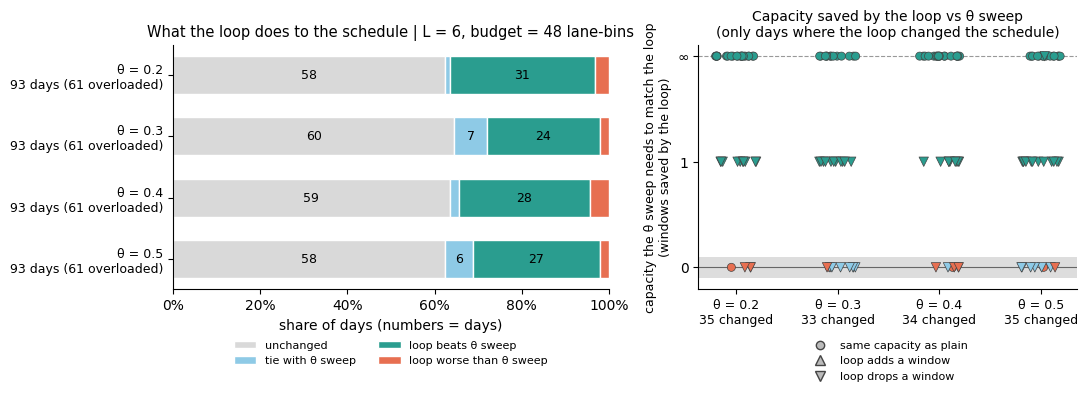

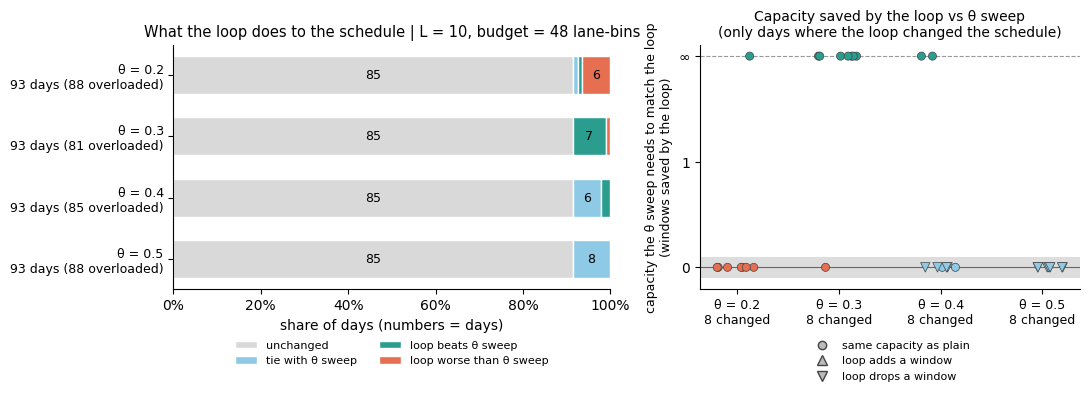

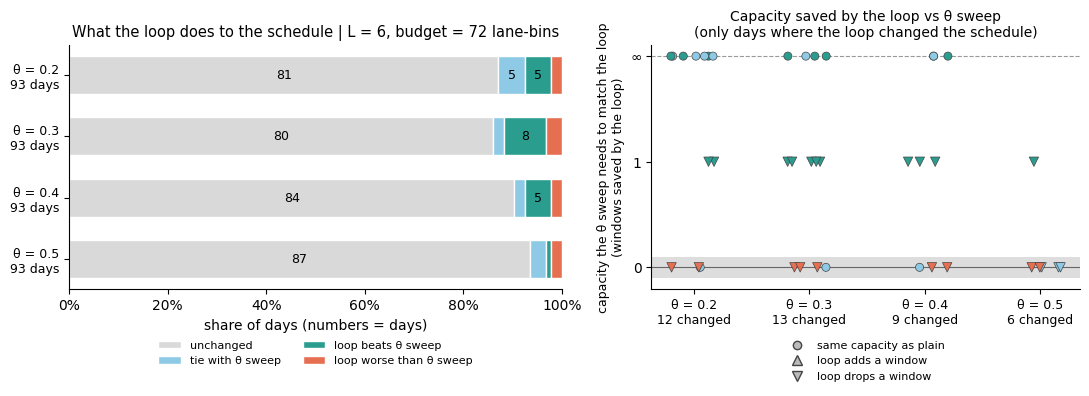

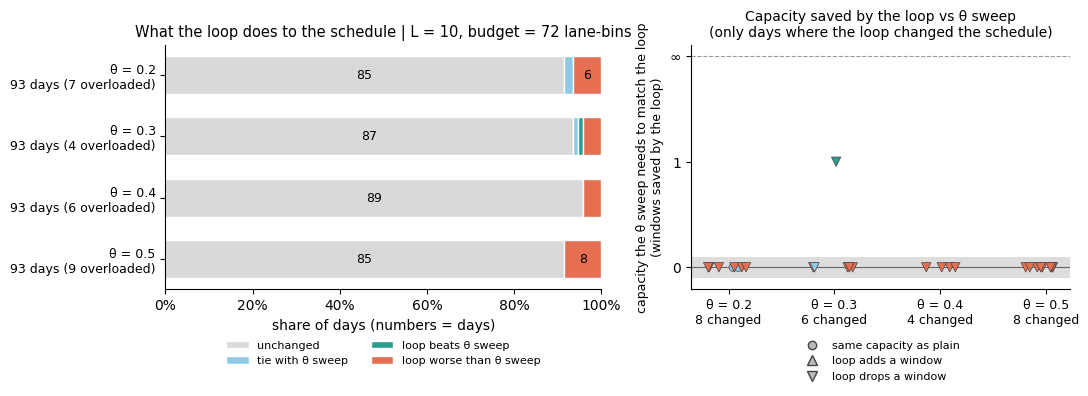

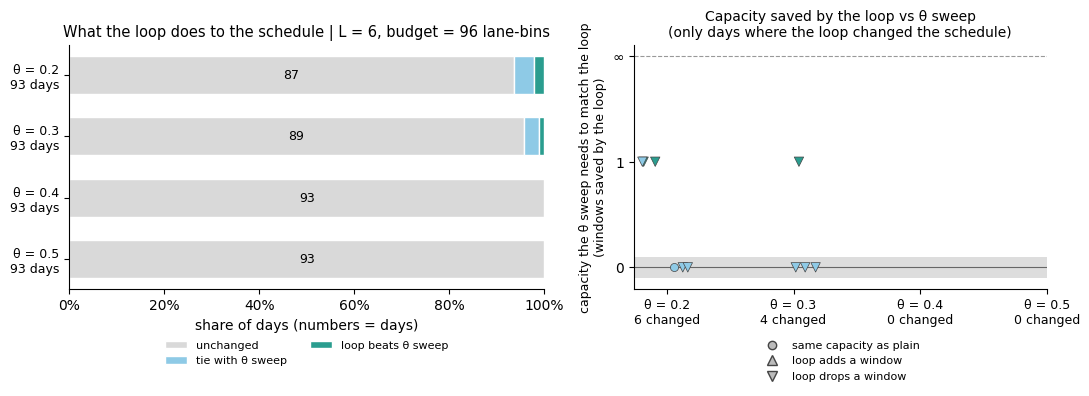

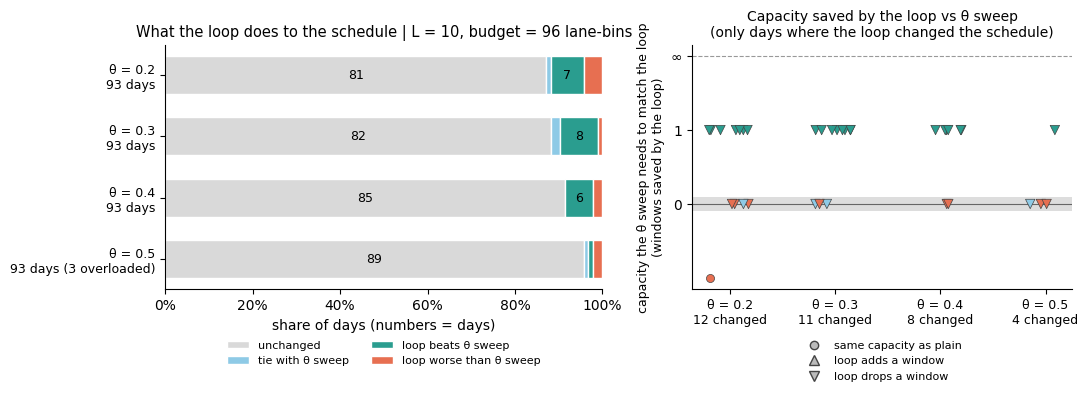

In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ORDER = ["unchanged", "tie with θ sweep", "loop beats θ sweep", "loop worse than θ sweep"]
COL = dict(zip(ORDER, ["#d9d9d9", "#8ecae6", "#2a9d8f", "#e76f51"]))

def plot_loop_verdict(df, title=None):
    d = df.copy()

    def cat(r):
        if not r["changed"]:               return "unchanged"
        if r["loop_beats_sweep"]:          return "loop beats θ sweep"
        if r["loop_worse_than_sweep"]:     return "loop worse than θ sweep"
        return "tie with θ sweep"
    d["cat"] = d.apply(cat, axis=1)

    thetas = sorted(d["theta"].unique())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})

    # ---- sinistra: cosa fa il loop, per θ
    for i, t in enumerate(thetas):
        g = d[d["theta"] == t]; left = 0.0
        for c in ORDER:
            n = int((g["cat"] == c).sum()); w = n / len(g)
            if n:
                a1.barh(i, w, left=left, color=COL[c], edgecolor="white", height=0.62, label=c)
                if w >= 0.05: a1.text(left + w/2, i, str(n), ha="center", va="center", fontsize=9)
            left += w
    n_ov = d[d["overloaded"].astype(bool)].groupby("theta").size().reindex(thetas, fill_value=0)
    a1.set_yticks(range(len(thetas)))
    a1.set_yticklabels([f"θ = {t:g}\n{int((d['theta']==t).sum())} days" +
                        (f" ({int(n_ov[t])} overloaded)" if n_ov[t] else "") for t in thetas], fontsize=9)
    a1.invert_yaxis(); a1.set_xlim(0, 1); a1.set_xlabel("share of days (numbers = days)")
    a1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    h, l = a1.get_legend_handles_labels(); u = dict(zip(l, h))
    a1.legend([u[c] for c in ORDER if c in u], [c for c in ORDER if c in u], fontsize=8,
              loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    a1.set_title(f"What the loop does to the schedule | {title}", fontsize=10.5)

    # ---- destra: capacità risparmiata rispetto allo sweep (cap_gap, in finestre)
    ch = d[d["changed"]].copy()
    ch["gap"] = ch["cap_gap"] / ch["L"]                       # lane-bin -> numero di finestre
    fin = ch.loc[np.isfinite(ch["gap"]), "gap"]
    ytop = max(1.0, (fin.max() if len(fin) else 0)) + 1.0     # livello "∞"
    ch["y"] = np.where(np.isinf(ch["gap"]), ytop, ch["gap"])
    ch["dcap"] = ch["cap_B"] - ch["cap_A"]
    ch["mk"] = np.where(ch["dcap"] > 1e-9, "^", np.where(ch["dcap"] < -1e-9, "v", "o"))
    rng = np.random.default_rng(0)

    for i, t in enumerate(thetas):
        g = ch[ch["theta"] == t]
        if g.empty: continue
        x = i + rng.uniform(-0.2, 0.2, len(g))
        for mk in ("o", "^", "v"):
            m = (g["mk"] == mk).values
            if m.any():
                a2.scatter(x[m], g["y"].values[m], c=[COL[c] for c in g["cat"].values[m]], marker=mk,
                           edgecolor="#444", linewidth=0.5, s=46 if mk != "o" else 34, zorder=3)
    a2.axhline(0, color="#666", lw=0.8, zorder=1)
    a2.axhspan(-0.1, 0.1, color="#cfcfcf", alpha=0.7, lw=0, zorder=0)
    a2.axhline(ytop, color="#999", lw=0.8, ls="--", zorder=1)
    ticks = list(range(0, int(ytop))) + [ytop]
    a2.set_yticks(ticks); a2.set_yticklabels([str(t) for t in ticks[:-1]] + ["∞"])
    a2.set_xticks(range(len(thetas)))
    a2.set_xticklabels([f"θ = {t:g}\n{int((ch['theta']==t).sum())} changed" for t in thetas], fontsize=9)
    a2.set_ylabel("capacity the θ sweep needs to match the loop\n(windows saved by the loop)", fontsize=9)
    a2.set_title("Capacity saved by the loop vs θ sweep\n(only days where the loop changed the schedule)", fontsize=10)
    hs = [Line2D([], [], marker="o", ls="", mfc="#bbb", mec="#444", ms=6, label="same capacity as plain"),
          Line2D([], [], marker="^", ls="", mfc="#bbb", mec="#444", ms=7, label="loop adds a window"),
          Line2D([], [], marker="v", ls="", mfc="#bbb", mec="#444", ms=7, label="loop drops a window")]
    a2.legend(handles=hs, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False)

    for ax in (a1, a2):
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.tight_layout(); return fig

for (lb, l), g in df_loop.groupby(["lane_bins", "L"]):
    fig = plot_loop_verdict(g, title=f"L = {l}, budget = {lb} lane-bins")
    fig.savefig(f"loop_verdict_lb{lb}_L{l}.png", dpi=200, bbox_inches="tight")
    plt.show()

#### Testing improve coverage